> **Language & Quick Links**: [🇰🇷 Korean (`notebooks/ko/stage2_wiki_and_semantic_graph_ko.ipynb`)](../ko/stage2_wiki_and_semantic_graph_ko.ipynb) · **🇺🇸 English (Current Folder: `notebooks/en/`)** ｜ [Methodology Guide](../../methodology/en/02_stage2_wiki_and_semantic_graph_en.md) ｜ [Notebook Index (README)](../README.md) ｜ [Open Live Studio Tab](https://agentic-ontology-starter-lwrlf7yogq-du.a.run.app/?tab=stage2)
>
> **Lifecycle Navigation**: [0. End-to-End Overview](./stage0_overview_walkthrough_en.ipynb) → [Stage 1 · Prepare & Analyze](./stage1_asset_and_cq_en.ipynb) → **[▶ Stage 2 · Parse & Integrate](./stage2_wiki_and_semantic_graph_en.ipynb)** → [Stage 3 · Build Property Graph](./stage3_property_graph_bigquery_spanner_en.ipynb) → [Stage 4 · Build Agent & Answer](./stage4_agent_and_mcp_execution_en.ipynb) → [Stage 5 · Verify & Evaluate](./stage5_lineage_and_evaluation_en.ipynb)

---

# Stage 2. [Parse & Integrate] Ready-to-Use 3-Layer OKF Wiki, Business Rules/Workflows (`W1~W3`) & Semantic Graph
## Step 2.1 SHA-256 Hash-Anchored Chunks & OKF v0.2 3-Layer Wiki · Step 2.2 Domain Rule Binding & Semantic Graph (`Entity=Node`, `Concept=Edge`)

Stage 2 connects to the **Ready-to-Use Knowledge Resources** provisioned from **Phase 3 (Parsing)** and **Phase 4 (Integration)**: `DOC_CHUNK_001~005` with deterministic **SHA-256 hash anchors (`anchor_<12hex>`)**, the **Andrej Karpathy 3-Layer LLM-Wiki (`summary.md`, `entities.md`, `concepts.md`, `rules.md`)**, **4 Business Rules (`business_rules.json`) & 3 Decision Workflows (`business_workflows.json`, `W1~W3`)**, and the **Semantic Ontology Graph (`ontology.jsonld`, `tb_domain_rules`, `edge_rule_applies_to_plan`)** synced across GCS (`gs://seanjung-poc-starter-ontology/ontology/`) and BigQuery.

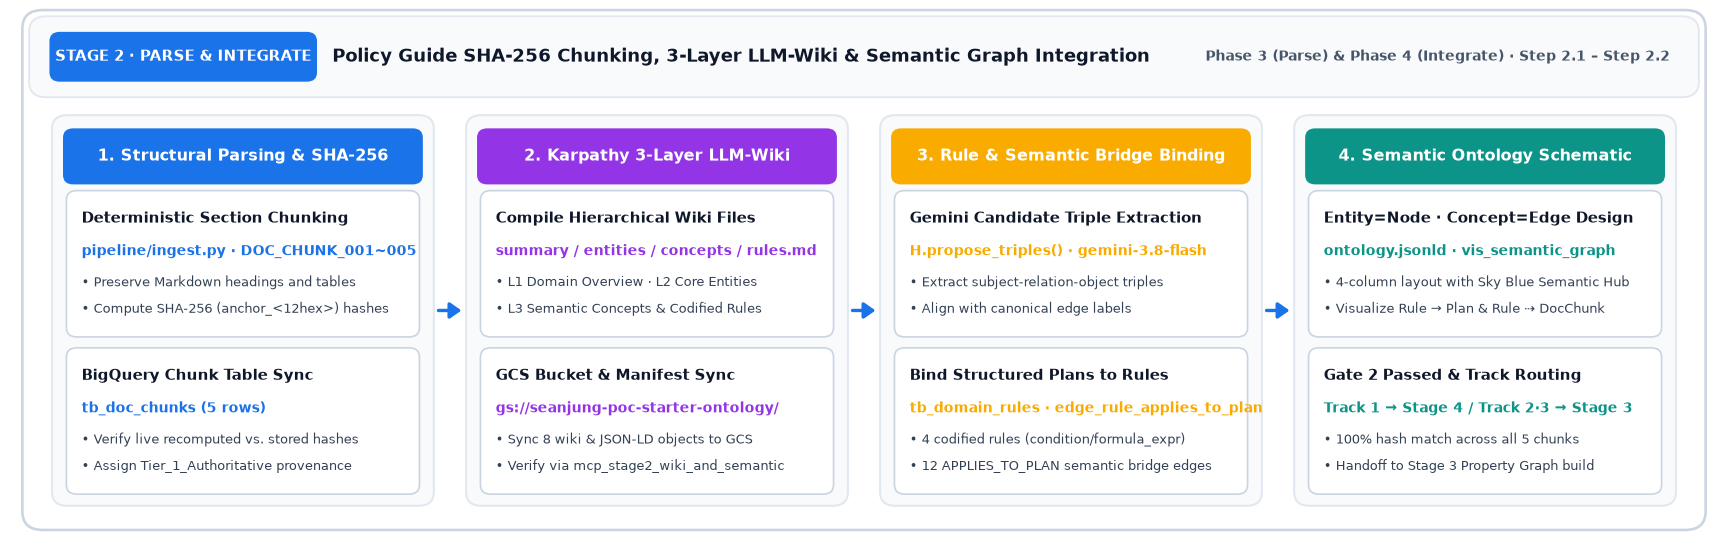


In [ ]:
%load_ext bigframes
import sys
from pathlib import Path
for _p in (Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent):
    if (_p / "nb_helpers.py").exists() and str(_p) not in sys.path:
        sys.path.insert(0, str(_p))
import pandas as pd
import nb_helpers as H
from src.agent.mcp_server import DomainMcpServer
H.setup("en")
server = DomainMcpServer()


### 1. [Phase 3a: Parsing] Raw Policy Markdown (`01_guides/*.md`) Chunking & SHA-256 Anchor Integrity Check (`H.parse_guides_live_demo`)


In [ ]:
df_parsed = H.parse_guides_live_demo()
H.show(df_parsed)


In [ ]:
%%bqsql df_bq_chunks
SELECT chunk_id, source_file, section_title, trust_tier, content_sha256,
       CHAR_LENGTH(content) AS char_len, REGEXP_REPLACE(SUBSTR(content, 1, 85), r'\s*\([^)]*[^\x00-\x7F][^)]*\)', '') AS content_preview
FROM `seanjung-poc.starter_ontology_dw.tb_doc_chunks`
ORDER BY chunk_id


In [ ]:
H.show(df_bq_chunks)


### 2. [Phase 3b: Wiki Compilation & GCS Sync] Karpathy 3-Layer LLM-Wiki (`summary.md`, `entities.md`, `concepts.md`, `rules.md`) & `stage2_resource_check`


In [ ]:
df_wiki, manifest = H.wiki_compilation_summary()
H.md(f"**GCS Manifest Status**: `{manifest['status']}` · Bucket `{manifest['gcs_uri']}` · Uploaded Objects `{len(manifest['uploaded_gcs_objects'])}` · Loaded BQ Tables `{manifest['validation']['bigquery_tables_loaded']}`")
H.show(df_wiki)
for fname in ("summary.md", "entities.md", "concepts.md", "rules.md"):
    H.show_md_file(H.ROOT / "data/llm_wiki/en" / fname, max_lines=22)
res_s2 = server.execute_tool("stage2_resource_check", {"steps": ["compile_3layer_wiki", "extract_hash_anchors", "bind_semantic_bridges"]})
H.show_tool(res_s2, "anchored_chunks")


### 3. [Phase 4a: Semantic Integration] Live Gemini (`gemini-3.8-flash`) Candidate Triple Extraction & Rule-to-Plan Semantic Bridge Tables (`%%bqsql`)


In [ ]:
triples = H.propose_triples(["DOC_CHUNK_001", "DOC_CHUNK_003", "DOC_CHUNK_004"])
H.show(triples)


In [ ]:
%%bqsql df_rules
SELECT r.rule_id,
       CASE r.rule_id WHEN 'RULE_SUBSIDY_CAP' THEN 'Public Subsidy & 15% Retail Additional Subsidy Cap Rule' WHEN 'RULE_PENALTY_180D' THEN '180-Day Baseline (45,000 KRW) Mandatory Retention & Prorated Penalty Rule' WHEN 'RULE_WELFARE_EXEMPT' THEN 'Senior, Youth & Welfare Downgrade Penalty Exemption Rule' WHEN 'RULE_TCO_24M' THEN '24-Month Public Subsidy vs. 25% Selective Contract TCO Comparison Rule' ELSE r.rule_id END AS rule_name,
       r.rule_category, r.condition_expr, r.formula_expr,
       r.source_chunk_id, c.section_title, c.content_sha256
FROM `seanjung-poc.starter_ontology_dw.tb_domain_rules` r
JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` c ON c.chunk_id = r.source_chunk_id
ORDER BY r.rule_id


In [ ]:
%%bqsql df_rule_plan
SELECT e.edge_id, e.rule_id, e.plan_id, p.plan_name, p.monthly_fee_krw,
       CASE e.rule_id WHEN 'RULE_SUBSIDY_CAP' THEN 'Public & 15% Additional Subsidy Cap Applied' WHEN 'RULE_PENALTY_180D' THEN '180-Day Baseline Retention Mandatory' WHEN 'RULE_WELFARE_EXEMPT' THEN 'Senior/Welfare Penalty Exemption Target' WHEN 'RULE_TCO_24M' THEN '24M Subsidy vs. Selective Contract TCO Applied' ELSE 'APPLIES_TO_PLAN' END AS relation_label_ko,
       e.source_chunk_id
FROM `seanjung-poc.starter_ontology_dw.edge_rule_applies_to_plan` e
JOIN `seanjung-poc.starter_ontology_dw.tb_plan_master` p USING (plan_id)
ORDER BY e.rule_id, p.monthly_fee_krw DESC


In [ ]:
H.show(df_rules)
H.show(df_rule_plan)


### 4. [Phase 4b: Semantic Graph Design & Schematics] OKF v0.2 `ontology.jsonld` & Semantic Ontology Graph (`Entity=Node`, `Concept=Edge`)


In [ ]:
ont = H.read_json("data/output/ontology.jsonld")
H.show(pd.DataFrame(ont.get("@graph", [])))
H.draw_semantic_design_graph()

rp = H.pdf(df_rule_plan)
nodes, edges = [], []
for r in rp.itertuples():
    nodes.append({"id": r.source_chunk_id, "name": r.source_chunk_id, "color": "#9334E6", "layer": 0})
    nodes.append({"id": r.rule_id, "name": r.rule_id, "color": "#F9AB00", "layer": 1})
    nodes.append({"id": r.plan_name, "name": r.plan_name, "color": "#0284c7", "layer": 2})
    e_lbl = r.relation_label_ko if H.LANG == "ko" else "APPLIES_TO_PLAN"
    edges.append({"src": r.rule_id, "dst": r.plan_name, "label": e_lbl})
    edges.append({"src": r.rule_id, "dst": r.source_chunk_id, "label": "GROUNDED_IN", "style": "dashed"})
uniq_nodes = list({n["id"]: n for n in nodes}.values())
H.draw_graph(uniq_nodes, edges,
             "Live BigQuery DocChunk ⇠ Rule (GROUNDED_IN) & Rule → Plan (APPLIES_TO_PLAN) Semantic Bridge Graph",
             layout="layers", figsize=(11.8, 5.4), node_size=1850,
             legend={"Doc Chunk (#9334E6)": "#9334E6", "Domain Rule (#F9AB00)": "#F9AB00", "Tariff Plan (#0284c7)": "#0284c7"})


### 5. [Ontology Self-Sufficiency Check] Do entity, concept, and rule wiki resources carry their own source evidence?

**Recommended method (Reference Standard: LG U+ & LG H&H 12-Tab Studio)**
- Each entity/concept document in the ontology layer carries the key facts summarized from the source, with source values, paragraph anchors and short quotes. Values not present in the source are not allowed.
- Graph design and graph data load work from the ontology folder alone (frontmatter `graph.properties` single-source authoring, no hard-coded INSERTs).
- Search reads ontology wiki and business rules/workflows (`W1~W3`) first, cross-verifying against `DOC_CHUNK` SHA-256 anchors.

**The starter's Ready-to-Use resource structure**
- Instead of exposing heavy internal compilers, the Starter connects directly (`src/resource_connector.py`) to the Ready-to-Use 3-Layer Wiki files (`summary.md`, `entities.md`, `concepts.md`, `rules.md`), `ontology.jsonld`, and business rules/workflows (`business_rules.json`, `business_workflows.json` `W1~W3`) on GCS (`gs://seanjung-poc-starter-ontology/ontology/`).
- Every rule in `rules.md` and `business_rules.json` carries a deterministic `DOC_CHUNK_001~005` SHA-256 anchor.

The cell below counts, in the local wiki files and `ontology.jsonld`, the items and the items carrying a chunk anchor (`DOC_CHUNK_*` or `anchor_<12hex>`).


In [ ]:
import re
wiki_dir = H.ROOT / "data/llm_wiki" / H.LANG
anchor_rows = []
for fname in ("entities.md", "concepts.md", "rules.md"):
    items = [ln for ln in (wiki_dir / fname).read_text(encoding="utf-8").splitlines() if re.match(r"^(- `|### `|\d+\. `)", ln)]
    anchor_rows.append({"file": f"data/llm_wiki/{H.LANG}/{fname}", "items": len(items),
                        "items_with_chunk_anchor": sum(bool(re.search(r"DOC_CHUNK_\d+|anchor_[0-9a-f]{12}", ln)) for ln in items)})
ont_chunks = [g for g in ont.get("@graph", []) if g.get("@type") == "DocChunk"]
anchor_rows.append({"file": "data/output/ontology.jsonld (DocChunk)", "items": len(ont_chunks),
                    "items_with_chunk_anchor": sum(bool(g.get("hashAnchor")) for g in ont_chunks)})
H.show(pd.DataFrame(anchor_rows))


### Q&A
- **Q.** How are unstructured policy paragraphs semantically integrated with structured tariff plan tables?
  - **A.** Policy guides are segmented into `DOC_CHUNK_001~005` with deterministic `anchor_<12hex>` SHA-256 hashes, domain rules are codified in `tb_domain_rules` (4 rules) and `business_rules.json`, and bound to structured `plan_id` rows via `edge_rule_applies_to_plan` (12 edges).

### Data Analysis Key Findings
- Re-computing SHA-256 anchors across all 5 parsed chunks (`DOC_CHUNK_001~005`) matched `tb_doc_chunks.content_sha256` in BigQuery (`sha256_match=True` for all 5).
- All 4 layers of the LLM-Wiki (`summary.md`, `entities.md`, `concepts.md`, `rules.md`) and `ontology.jsonld` (8 objects total) are synced to GCS (`LIVE_GCP_SYNCED`).
- 4 codified domain rules connect to the 6 tariff plans via 12 `APPLIES_TO_PLAN` semantic bridge edges, grounded in `DOC_CHUNK_001~005`.

### Insights or Next Steps
- Track 1 (Lite) deployments can jump directly to `Stage 4 (Build Agent & Answer)`, while Track 2/3 deployments proceed to `Stage 3 (Build Property Graph)` for Zero-ETL BigQuery/Spanner Property Graph provisioning.

---
> **Next Navigation**: [⬅️ Stage 1 · Prepare & Analyze](./stage1_asset_and_cq_en.ipynb) ｜ [🏠 0. Overview Home](./stage0_overview_walkthrough_en.ipynb) ｜ [➡️ Stage 3 · Build Property Graph](./stage3_property_graph_bigquery_spanner_en.ipynb) ｜ [🌐 Korean Version](../ko/stage2_wiki_and_semantic_graph_ko.ipynb) ｜ [📖 Methodology Doc](../../methodology/en/02_stage2_wiki_and_semantic_graph_en.md)
